# Практическая работа №3: Линейная регрессия

## Задание №1

Используется набор данных `Auto`.

1. Воспользуйтесь функцией `lm()` для подгонки простой линейной регрессии с `mpg` в качестве отклика и `horsepower` в качестве предиктора. Примените функцию `summary()` для вывода результатов на экран. Прокомментируйте эту выведенную информацию, ответитв на следующие вопросы:
  * Есть ли линейная связь между предиктором и откликом?
  * Насколько сильна связь между предиктором и откликом?
  * Каково направление связь между предиктором и откликом?
  * Чему равно модельное значение `mpg` при `horsepower = 98`? Каковы соответствующие 95%-ные доверительные интервалы для регрессионной прямой и для предсказанного значения?

In [18]:
library(ISLR)
data(Auto)

lm1 <- lm(mpg ~ horsepower, data = Auto)
summary(lm1)

predict(lm1, newdata = data.frame(horsepower = 98), interval = "confidence")
predict(lm1, newdata = data.frame(horsepower = 98), interval = "prediction")


Call:
lm(formula = mpg ~ horsepower, data = Auto)

Residuals:
     Min       1Q   Median       3Q      Max 
-13.5710  -3.2592  -0.3435   2.7630  16.9240 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 39.935861   0.717499   55.66   <2e-16 ***
horsepower  -0.157845   0.006446  -24.49   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.906 on 390 degrees of freedom
Multiple R-squared:  0.6059,	Adjusted R-squared:  0.6049 
F-statistic: 599.7 on 1 and 390 DF,  p-value: < 2.2e-16


,fit,lwr,upr
1,24.46708,23.97308,24.96108


,fit,lwr,upr
1,24.46708,14.8094,34.12476


1. Есть линейная связь между предиктором и откликом + она высоко статистически значима, поскольку:
    * Коэффициент при horsepower равен −0.157845, его стандартная ошибка — 0.006446
    * t‑статистика = −24.49, p‑значение < 2.2e‑16 (много меньше 0.05)
    * F‑статистика модели = 599.7, p‑значение < 2.2e‑16 — модель в целом значима
    * Нулевая гипотеза $H_0: \beta_1$ = 0 уверенно отвергается
2. Связь между предиктором и откликом умеренно сильная
    * Multiple $R^2$ = 0.6059 — модель объясняет ≈ 60.6% вариации mpg
    * Adjusted $R^2$ = 0.6049 — почти не отличается (один предиктор)
    * RSE = 4.906 mpg — типичное отклонение фактического mpg от предсказанного составляет примерно 4.9
3. Направление связи отрицательное (Коэффициент $\beta_1$ = −0.157845)
4. Модельное значение при horsepower = 98: $\widehat{\text{mpg}} = 39.935861 - 0.157845·98 \approx 24.47$
    * 95%-й доверительный интервал для линии регрессии примерно [23.97; 24.96] — с 95% вероятностью среднее значение mpg для всех автомобилей с horsepower = 98 лежит в этом диапазоне
    * 95%-й интервал предсказания для отдельного наблюдения примерно [14.81; 34.12] — с 95% вероятностью mpg конкретного автомобиля с мощностью 98 л.с. попадет в этот (более широкий) диапазон. Он шире, потому что учитывает не только неопределенность положения линии, но и остаточный разброс вокруг нее (RSE примерно 4.9)

2. Постройте график зависимости отклика от предиктора вместе с набором данных.

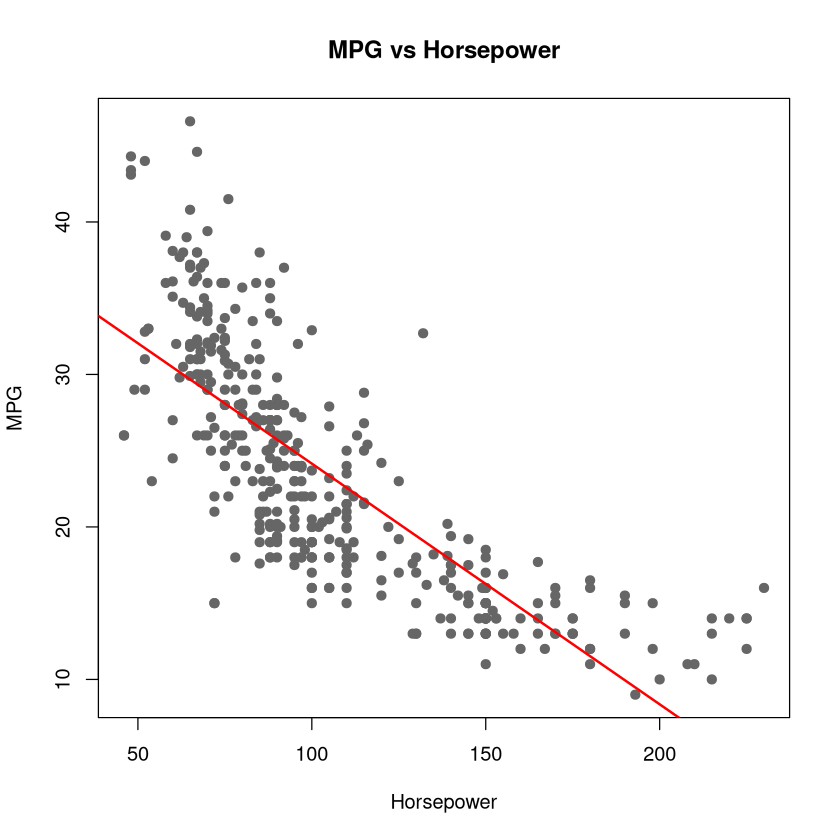

In [19]:
plot(Auto$horsepower, Auto$mpg, xlab = "Horsepower", ylab = "MPG", main = "MPG vs Horsepower", pch = 19, col = "gray40")
abline(lm1, col = "red", lwd = 2)

3. Воспользуйтесь функцией `plot()` для построения диагностических графиков для модели, подогнанной по методу наименьших квадратов. Прокомментируйте любые обнаруженные Вами проблемы с этой моделью.

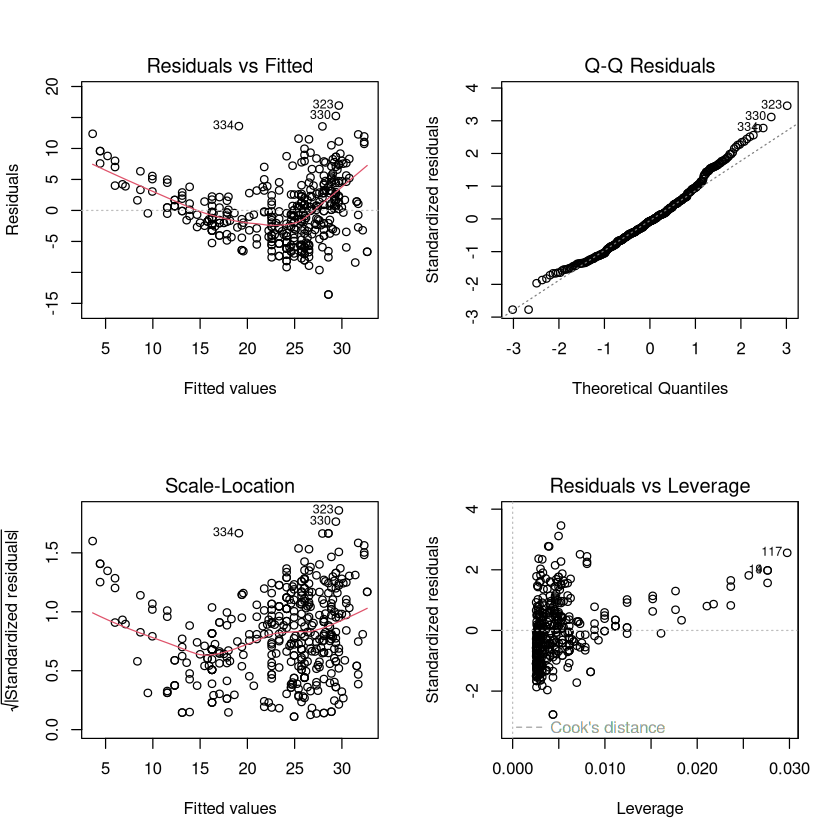

In [20]:
par(mfrow = c(2, 2))
plot(lm1)
par(mfrow = c(1, 1))

Проблемы модели:

* График рассеяния и Residuals vs Fitted: прослеживается явная нелинейная зависимость. Прямая регрессия завышает предсказания на малых/средних мощностях и занижает на высоких. На графике остатков видна параболическая структура (улыбка), что нарушает допущение о линейности
* Normal Q-Q: распределение остатков имеет более тяжелый правый хвост, чем нормальное. Заметно выделяются наблюдения 323 и 330 (возможные выбросы), но в целом основная масса остатков распределена нормально
* Scale-Location: красная линия имеет дугообразную форму, показывая, что дисперсия остатков минимальна при средних предсказанных значениях и увеличивается по краям
* Residuals vs Leverage: есть наблюдение с повышенным рычагом (например, 117), однако все точки лежат в пределах границ расстояния Кука, поэтому критического влияния на оценки коэффициентов нет

Вывод: Простая линейная модель плохо описывает данные из-за нелинейной связи между мощностью и расходом топлива. Необходимо использовать преобразования переменных (например, логарифмирование) для улучшения качества модели

## Задание №2

Используется набор данных `Auto`.

1. Постройте матрицу диаграмм рассеяния, которая включает все переменные из этой таблицы данных. Для этого воспользуйтесь функцией `pairs()`. Изучите справку по данной функции. Прокомментируйте полученный график.

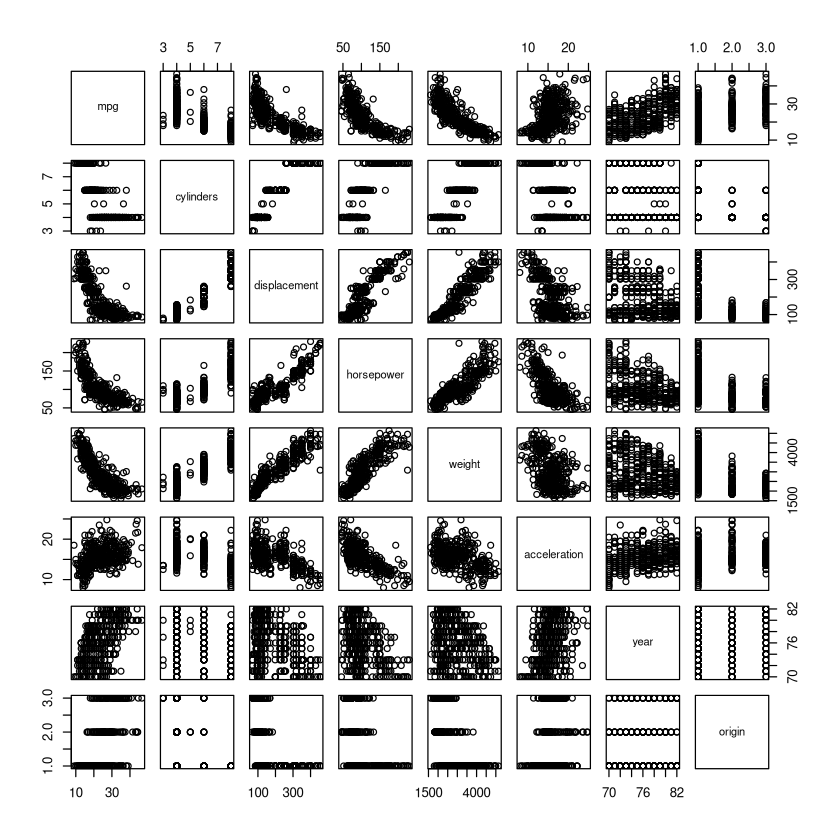

In [21]:
pairs(Auto[, sapply(Auto, is.numeric)])

Комментарий к матрице диаграмм рассеяния (pairs):

1. Связь с откликом (mpg):
   Переменная `mpg` демонстрирует отчетливую отрицательную связь с `displacement`, `horsepower`, `weight` и `cylinders`. Чем больше эти показатели, тем ниже экономичность. Наблюдается слабая положительная связь с `year` (более новые автомобили экономичнее). С `acceleration` и `origin` явной линейной связи не видно. Форма облака `mpg` vs `horsepower`, `mpg` vs `displacement` и `mpg` vs `weight` имеет нелинейный (вогнутый) характер.

2. Мультиколлинеарность предикторов:
   Между предикторами (особенно `displacement`, `cylinders`, `weight`, `horsepower`) видна очень сильная положительная корреляция. Это говорит о наличии мультиколлинеарности: автомобили с большим весом, как правило, имеют большой объем двигателя и высокую мощность.

3. Структура данных:
   Переменные `cylinders` и `origin` принимают ограниченное число значений, поэтому на графиках образуют полосы. Переменная `year` распределена равномерно по диапазону. Облако точек `acceleration` содержит несколько заметных выбросов (машины с аномально высоким ускорением).

2. Вычислите корреляционную матрицу для всех переменных, используя функцию `соr()`. Вам потребуется исключить из расчетов качественную переменную `name`.

In [22]:
cor(Auto[, -9])

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
mpg,1.0000000,-0.7776175,-0.8051269,-0.7784268,-0.8322442,0.4233285,0.5805410,0.5652088
cylinders,-0.7776175,1.0000000,0.9508233,0.8429834,0.8975273,-0.5046834,-0.3456474,-0.5689316
displacement,-0.8051269,0.9508233,1.0000000,0.8972570,0.9329944,-0.5438005,-0.3698552,-0.6145351
horsepower,-0.7784268,0.8429834,0.8972570,1.0000000,0.8645377,-0.6891955,-0.4163615,-0.4551715
weight,-0.8322442,0.8975273,0.9329944,0.8645377,1.0000000,-0.4168392,-0.3091199,-0.5850054
acceleration,0.4233285,-0.5046834,-0.5438005,-0.6891955,-0.4168392,1.0000000,0.2903161,0.2127458
year,0.5805410,-0.3456474,-0.3698552,-0.4163615,-0.3091199,0.2903161,1.0000000,0.1815277
origin,0.5652088,-0.5689316,-0.6145351,-0.4551715,-0.5850054,0.2127458,0.1815277,1.0000000


3. Воспользуйтесь функцией `lm()` для подгонки множественной линейной регрессии с `mpg` в качестве отклика и всех других переменных, за исключением `name`, в качестве предикторов. Примените функцию `summary()` для вывода результатов на экран. Прокомментируйте эту выведенную информацию, ответитв на следующие вопросы:
  * Имеется ли связь между предикторами и откликом?
  * Какие предикторы проявляют статистически значимую связь с откликом?
  * О чем говорит коэффициент переменной `year`?

In [23]:
lm2 <- lm(mpg ~ . - name, data = Auto)
summary(lm2)


Call:
lm(formula = mpg ~ . - name, data = Auto)

Residuals:
    Min      1Q  Median      3Q     Max 
-9.5903 -2.1565 -0.1169  1.8690 13.0604 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)    
(Intercept)  -17.218435   4.644294  -3.707  0.00024 ***
cylinders     -0.493376   0.323282  -1.526  0.12780    
displacement   0.019896   0.007515   2.647  0.00844 ** 
horsepower    -0.016951   0.013787  -1.230  0.21963    
weight        -0.006474   0.000652  -9.929  < 2e-16 ***
acceleration   0.080576   0.098845   0.815  0.41548    
year           0.750773   0.050973  14.729  < 2e-16 ***
origin         1.426141   0.278136   5.127 4.67e-07 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.328 on 384 degrees of freedom
Multiple R-squared:  0.8215,	Adjusted R-squared:  0.8182 
F-statistic: 252.4 on 7 and 384 DF,  p-value: < 2.2e-16


1. Есть связь между предикторами и откликом. F-статистика модели равна 252.4, а p-value < 2.2e-16 (что значительно меньше 0.05). Нулевая гипотеза о том, что все коэффициенты при предикторах равны нулю, уверенно отвергается. Модель объясняет 82.15% дисперсии отклика (Multiple R-squared = 0.8215)

2. При уровне значимости $\alpha = 0.05$ статистически значимыми являются:
  - `displacement` (p-value = 0.00844)
  - `weight` (p-value < 2e-16)
  - `year` (p-value < 2e-16)
  - `origin` (p-value = 4.67e-07)

Остальные предикторы (`cylinders`, `horsepower`, `acceleration`) незначимы (их p-value больше 0.05).

3. Коэффициент при `year` равен 0.750773. Это означает, что при фиксированных остальных параметрах каждый следующий модельный год выпуска автомобиля (year) дает прибавку к экономичности (mpg) в среднем на 0.75 миль на галлон. Это отражает технологический прогресс: более новые автомобили эффективнее

4. Воспользуйтесь функцией `plot()` для построения диагностических графиков для этой линейной регрессионной модели. Прокомментируйте любые обнаруженные вами проблемы с этой моделью. Указывают ли остатки на наличие каких-либо необычно больших выбросов? Указывает ли график значений показателя разбалансировки на наличие наблюдений с необычно высокой разбалансировкой?

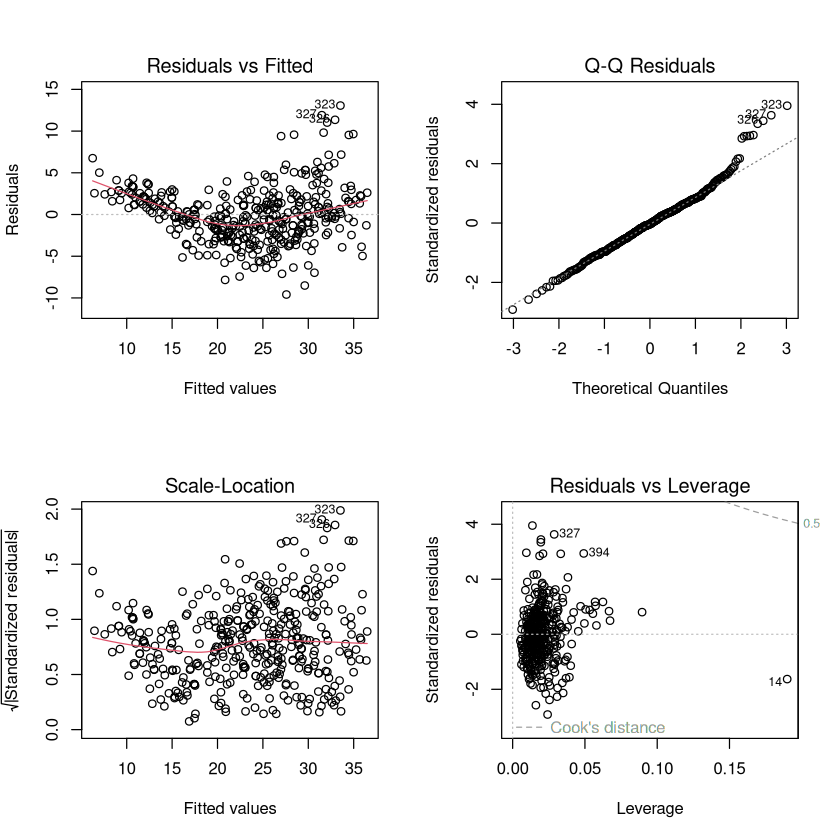

In [24]:
par(mfrow = c(2, 2))
plot(lm2)
par(mfrow = c(1, 1))

Ответы на вопросы:
* Да, на графике Normal Q-Q и Residuals vs Fitted видны точки с остатками, превышающими по модулю 10 (например, наблюдения 327, 323 и 326), что можно считать выбросами.
* Да, на графике Residuals vs Leverage есть наблюдения (с правой стороны графика), которые имеют высокий рычаг (Leverage). Они могут оказывать повышенное влияние на оценки коэффициентов регрессии.


Комментарий к диагностическим графикам множественной модели:

* Residuals vs Fitted: На графике остатков видна выраженная U-образная (нелинейная) структура. Точки образуют волну — это говорит о том, что модель не улавливает какую-то нелинейную зависимость, и допущение о линейности нарушено.
* Normal Q-Q: В правом хвосте графика (теоретические квантили >= 2) наблюдается заметное отклонение от прямой. Это указывает на то, что остатки имеют более тяжелый правый хвост, чем нормальное распределение.
* Scale-Location: В отличие от простой модели, здесь красная линия не образует четкой U-образной формы. Она выглядит как почти горизонтальная прямая с легким искривлением (волнами). Это указывает на слабую, но заметную гетероскедастичность: дисперсия остатков имеет тенденцию немного увеличиваться при больших предсказанных значениях (справа), но общая картина не настолько драматична, как в модели `mpg ~ horsepower`. Нарушение допущения о постоянной дисперсии присутствует, но оно не является критическим.
* Residuals vs Leverage: На графике видны точки с высоким рычагом (Leverage > 0.02), особенно выделяются наблюдения под номерами 327 и 394. Однако они находятся в пределах пунктирной линии расстояния Кука, поэтому их влияние не является критическим.

5. Используйте символы `*` и `:` для подгонки регрессионных моделей с эффектами взаимодействия. Являются ли какие-либо взаимодействия статистически значимыми?

In [25]:
# '*' — главные эффекты + взаимодействие
lm_int1 <- lm(mpg ~ weight * horsepower, data = Auto)
summary(lm_int1)

# ':' — только взаимодействие (без главных эффектов)
lm_int2 <- lm(mpg ~ weight + horsepower + weight:horsepower, data = Auto)
summary(lm_int2)  # идентична lm_int1

# Несколько взаимодействий в полной модели
lm_int3 <- lm(mpg ~ (. - name)^2, data = Auto)
summary(lm_int3)


Call:
lm(formula = mpg ~ weight * horsepower, data = Auto)

Residuals:
     Min       1Q   Median       3Q      Max 
-10.7725  -2.2074  -0.2708   1.9973  14.7314 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)        6.356e+01  2.343e+00  27.127  < 2e-16 ***
weight            -1.077e-02  7.738e-04 -13.921  < 2e-16 ***
horsepower        -2.508e-01  2.728e-02  -9.195  < 2e-16 ***
weight:horsepower  5.355e-05  6.649e-06   8.054 9.93e-15 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.93 on 388 degrees of freedom
Multiple R-squared:  0.7484,	Adjusted R-squared:  0.7465 
F-statistic: 384.8 on 3 and 388 DF,  p-value: < 2.2e-16



Call:
lm(formula = mpg ~ weight + horsepower + weight:horsepower, data = Auto)

Residuals:
     Min       1Q   Median       3Q      Max 
-10.7725  -2.2074  -0.2708   1.9973  14.7314 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)        6.356e+01  2.343e+00  27.127  < 2e-16 ***
weight            -1.077e-02  7.738e-04 -13.921  < 2e-16 ***
horsepower        -2.508e-01  2.728e-02  -9.195  < 2e-16 ***
weight:horsepower  5.355e-05  6.649e-06   8.054 9.93e-15 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.93 on 388 degrees of freedom
Multiple R-squared:  0.7484,	Adjusted R-squared:  0.7465 
F-statistic: 384.8 on 3 and 388 DF,  p-value: < 2.2e-16



Call:
lm(formula = mpg ~ (. - name)^2, data = Auto)

Residuals:
    Min      1Q  Median      3Q     Max 
-7.6303 -1.4481  0.0596  1.2739 11.1386 

Coefficients:
                            Estimate Std. Error t value Pr(>|t|)   
(Intercept)                3.548e+01  5.314e+01   0.668  0.50475   
cylinders                  6.989e+00  8.248e+00   0.847  0.39738   
displacement              -4.785e-01  1.894e-01  -2.527  0.01192 * 
horsepower                 5.034e-01  3.470e-01   1.451  0.14769   
weight                     4.133e-03  1.759e-02   0.235  0.81442   
acceleration              -5.859e+00  2.174e+00  -2.696  0.00735 **
year                       6.974e-01  6.097e-01   1.144  0.25340   
origin                    -2.090e+01  7.097e+00  -2.944  0.00345 **
cylinders:displacement    -3.383e-03  6.455e-03  -0.524  0.60051   
cylinders:horsepower       1.161e-02  2.420e-02   0.480  0.63157   
cylinders:weight           3.575e-04  8.955e-04   0.399  0.69000   
cylinders:acceleration

Анализ взаимодействий:

1. В модели `lm(mpg ~ weight * horsepower)` взаимодействие `weight:horsepower` имеет p-value = 9.93e-15, что < 0.05 - это взаимодействие статистически значимо. Это означает, что эффект мощности (horsepower) на экономичность (mpg) зависит от веса автомобиля (и наоборот).
2. В полной модели со всеми возможными взаимодействиями `lm(mpg ~ (. - name)^2)` статистически значимыми (p < 0.05) оказались следующие взаимодействия:
   - `displacement:year` (p = 0.01352)
   - `acceleration:year` (p = 0.03033)
   - `acceleration:origin` (p = 0.00365)
   
Остальные взаимодействия незначимы. При этом добавление всех взаимодействий увеличивает число предикторов до 28, но Adjusted R-squared вырос до 0.8808. При этом многие главные эффекты (например, cylinders, weight) потеряли значимость из-за мультиколлинеарности.

6. Попробуйте применить несколько разных преобразований к переменным, таких как $ \log X $, $ \sqrt X $, $ X^2 $. Прокомментируйте свои находки.

In [26]:
# Логарифм отклика
lm_logy <- lm(log(mpg) ~ . - name, data = Auto)
summary(lm_logy)

# Логарифм предиктора в простой модели
lm_logx <- lm(mpg ~ log(horsepower), data = Auto)
summary(lm_logx)

# Корень из предиктора
lm_sqrt <- lm(mpg ~ sqrt(horsepower), data = Auto)
summary(lm_sqrt)

# Квадрат предиктора
lm_sq <- lm(mpg ~ I(horsepower^2), data = Auto)
summary(lm_sq)

# Для сравнения R^2
c(
    logy = summary(lm_logy)$r.squared,
    logx = summary(lm_logx)$r.squared,
    sqrtx = summary(lm_sqrt)$r.squared,
    sqx = summary(lm_sq)$r.squared,
    linear = summary(lm1)$r.squared
)


Call:
lm(formula = log(mpg) ~ . - name, data = Auto)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.40955 -0.06533  0.00079  0.06785  0.33925 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)    
(Intercept)   1.751e+00  1.662e-01  10.533  < 2e-16 ***
cylinders    -2.795e-02  1.157e-02  -2.415  0.01619 *  
displacement  6.362e-04  2.690e-04   2.365  0.01852 *  
horsepower   -1.475e-03  4.935e-04  -2.989  0.00298 ** 
weight       -2.551e-04  2.334e-05 -10.931  < 2e-16 ***
acceleration -1.348e-03  3.538e-03  -0.381  0.70339    
year          2.958e-02  1.824e-03  16.211  < 2e-16 ***
origin        4.071e-02  9.955e-03   4.089 5.28e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.1191 on 384 degrees of freedom
Multiple R-squared:  0.8795,	Adjusted R-squared:  0.8773 
F-statistic: 400.4 on 7 and 384 DF,  p-value: < 2.2e-16



Call:
lm(formula = mpg ~ log(horsepower), data = Auto)

Residuals:
     Min       1Q   Median       3Q      Max 
-14.2299  -2.7818  -0.2322   2.6661  15.4695 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)     108.6997     3.0496   35.64   <2e-16 ***
log(horsepower) -18.5822     0.6629  -28.03   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.501 on 390 degrees of freedom
Multiple R-squared:  0.6683,	Adjusted R-squared:  0.6675 
F-statistic: 785.9 on 1 and 390 DF,  p-value: < 2.2e-16



Call:
lm(formula = mpg ~ sqrt(horsepower), data = Auto)

Residuals:
     Min       1Q   Median       3Q      Max 
-13.9768  -3.2239  -0.2252   2.6881  16.1411 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)        58.705      1.349   43.52   <2e-16 ***
sqrt(horsepower)   -3.503      0.132  -26.54   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.665 on 390 degrees of freedom
Multiple R-squared:  0.6437,	Adjusted R-squared:  0.6428 
F-statistic: 704.6 on 1 and 390 DF,  p-value: < 2.2e-16



Call:
lm(formula = mpg ~ I(horsepower^2), data = Auto)

Residuals:
    Min      1Q  Median      3Q     Max 
-12.529  -3.798  -1.049   3.240  18.528 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)      3.047e+01  4.466e-01   68.22   <2e-16 ***
I(horsepower^2) -5.665e-04  2.827e-05  -20.04   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 5.485 on 390 degrees of freedom
Multiple R-squared:  0.5074,	Adjusted R-squared:  0.5061 
F-statistic: 401.7 on 1 and 390 DF,  p-value: < 2.2e-16


logy      logx     sqrtx       sqx    linear 
0.8795102 0.6683348 0.6437036 0.5073670 0.6059483

Сравнение преобразований (по значению $R^2$):

* `log(mpg) ~ ...` (логарифм отклика в полной модели): $R^2 = 0.8795$. Это лучший результат среди всех преобразований. Логарифмирование отклика значительно улучшает качество модели и помогает справиться с нелинейностью и гетероскедастичностью.
* `mpg ~ log(horsepower)`: $R^2 = 0.6683$. Логарифмирование предиктора в простой модели работает лучше, чем простая линейная регрессия ($R^2 = 0.6059$).
* `mpg ~ sqrt(horsepower)`: $R^2 = 0.6437$. Результат лучше, чем у простой линейной модели, но хуже, чем у логарифма.
* `mpg ~ I(horsepower^2)`: $R^2 = 0.5074$. Возведение предиктора в квадрат (без линейного члена) не дает улучшения.

Вывод: Логарифмическое преобразование отклика (log(mpg)) является наиболее эффективным. Логарифмирование предиктора (log(horsepower)) также улучшает качество модели по сравнению с исходной линейной зависимостью, так как зависимость между мощностью и экономичностью имеет убывающий характер.

## Задание №3

Используется набор данных `Carseats`. Для этого необходимо установить пакет `ISLR`.

1. Постройте множественную регрессионную модель для предсказания `Sales` на основе `Price`, `Urban` и `US`.

In [33]:
library(ISLR)
data(Carseats)

lm3 <- lm(Sales ~ Price + Urban + US, data = Carseats)
summary(lm3)


Call:
lm(formula = Sales ~ Price + Urban + US, data = Carseats)

Residuals:
    Min      1Q  Median      3Q     Max 
-6.9206 -1.6220 -0.0564  1.5786  7.0581 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 13.043469   0.651012  20.036  < 2e-16 ***
Price       -0.054459   0.005242 -10.389  < 2e-16 ***
UrbanYes    -0.021916   0.271650  -0.081    0.936    
USYes        1.200573   0.259042   4.635 4.86e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.472 on 396 degrees of freedom
Multiple R-squared:  0.2393,	Adjusted R-squared:  0.2335 
F-statistic: 41.52 on 3 and 396 DF,  p-value: < 2.2e-16


2. Приведите интерпретацию каждого коэффициента в модели. Будьте осторожны — некоторые переменные являются качественными!

In [34]:
round(summary(lm3)$coefficients, 4)

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),13.0435,0.6510,20.0357,0.0000
Price,-0.0545,0.0052,-10.3892,0.0000
UrbanYes,-0.0219,0.2717,-0.0807,0.9357
USYes,1.2006,0.2590,4.6347,0.0000


Интерпретация коэффициентов:

Таблица коэффициентов содержит оценки, стандартные ошибки, t-статистики и p-значения для каждого предиктора. Поскольку `Urban` и `US` — качественные переменные, R автоматически создал для них фиктивные (dummy) переменные с уровнями `Yes`/`No`, где `No` — базовый уровень (reference level).

* `(Intercept)` = 13.0435 — базовый уровень продаж (тыс. шт.) для магазина не в городе (Urban = No) и не в США (US = No) при `Price = 0`. Цена 0 — экстраполяция, но коэффициент задаёт точку отсчёта.
* `Price` = −0.0545 — при увеличении цены на $1 продажи в среднем падают на 0.0545 тыс. шт. (≈54.5 единиц) при прочих равных.
* `UrbanYes` = −0.0219 — разница в продажах между магазинами в городе и вне города. Магазины в городе продают в среднем на 0.022 тыс. шт. меньше, но эффект статистически незначим (p = 0.936), поэтому интерпретировать его как реальный эффект нельзя.
* `USYes` = 1.2006 — магазины в США продают в среднем на 1.2006 тыс. шт. больше, чем магазины не в США (при равной цене и местоположении). Эффект значим (p < 0.001).

3. Запишите модель в виде уравнения (помня о необходимости должным образом обходиться с качественными переменными).

Модель имеет вид:
$$ \widehat{Sales} = 13.043469 - 0.054459 \cdot Price - 0.021916 \cdot I(Urban=Yes) + 1.200573 \cdot I(US=Yes) $$
где $I(\cdot)$ — это индикаторная переменная, которая равна 1, если условие выполнено, и 0, если нет.

4. Для каких из предикторов вы можете отклонить нулевую гипотезу $ H_0: \beta_j = 0 $?

Мы можем отклонить нулевую гипотезу $H_0: \beta_j = 0$ для следующих предикторов:
* Price (p-value < 2e-16)
* USYes (p-value = 4.86e-06)
Для предиктора UrbanYes (p-value = 0.936) оснований отклонить нулевую гипотезу нет, он незначим.

5. Учитывая свой ответ на предыдущий вопрос, постройте модель только с теми предикторами, для которых было было обнаружено свидетельство в пользу их связи с откликом.

In [35]:
lm_carseats_best <- lm(Sales ~ Price + US, data = Carseats)
summary(lm_carseats_best)


Call:
lm(formula = Sales ~ Price + US, data = Carseats)

Residuals:
    Min      1Q  Median      3Q     Max 
-6.9269 -1.6286 -0.0574  1.5766  7.0515 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 13.03079    0.63098  20.652  < 2e-16 ***
Price       -0.05448    0.00523 -10.416  < 2e-16 ***
USYes        1.19964    0.25846   4.641 4.71e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.469 on 397 degrees of freedom
Multiple R-squared:  0.2393,	Adjusted R-squared:  0.2354 
F-statistic: 62.43 on 2 and 397 DF,  p-value: < 2.2e-16


6. Насколько хорошо модели из п. 1 и 5 описывают данные?

* Модель из п.1: $R^2 = 0.2393$, Adjusted $R^2 = 0.2335$, RSE = 2.472.
* Модель из п.5: $R^2 = 0.2393$, Adjusted $R^2 = 0.2354$, RSE = 2.469.

Вывод: Значения $R^2$ идентичны (0.2393), так как удаление незначимого предиктора `Urban` практически не влияет на объясненную дисперсию. Однако Adjusted $R^2$ у модели из п.5 чуть выше (0.2354 против 0.2335), потому что эта метрика штрафует за лишние предикторы. RSE у второй модели тоже немного меньше (2.469 против 2.472). Следовательно, модель из п.5 проще, содержит только значимые предикторы и описывает данные не хуже (а по скорректированным метрикам — даже чуть лучше). Обе модели объясняют лишь около 24% вариации продаж, то есть большая часть изменчивости `Sales` остается необъясненной — вероятно, в данных есть другие важные факторы

7. Используя модель из п. 5, рассчитайте 95%-ные доверительные интервалы для каждого коэффициента.

In [36]:
confint(lm_carseats_best, level = 0.95)

,2.5 %,97.5 %
(Intercept),11.79032020,14.27126531
Price,-0.06475984,-0.04419543
USYes,0.69151957,1.70776632


8. Имеются ли указания на наличие выбросов или наблюдений с высокой разбалансировкой в модели из п. 5?

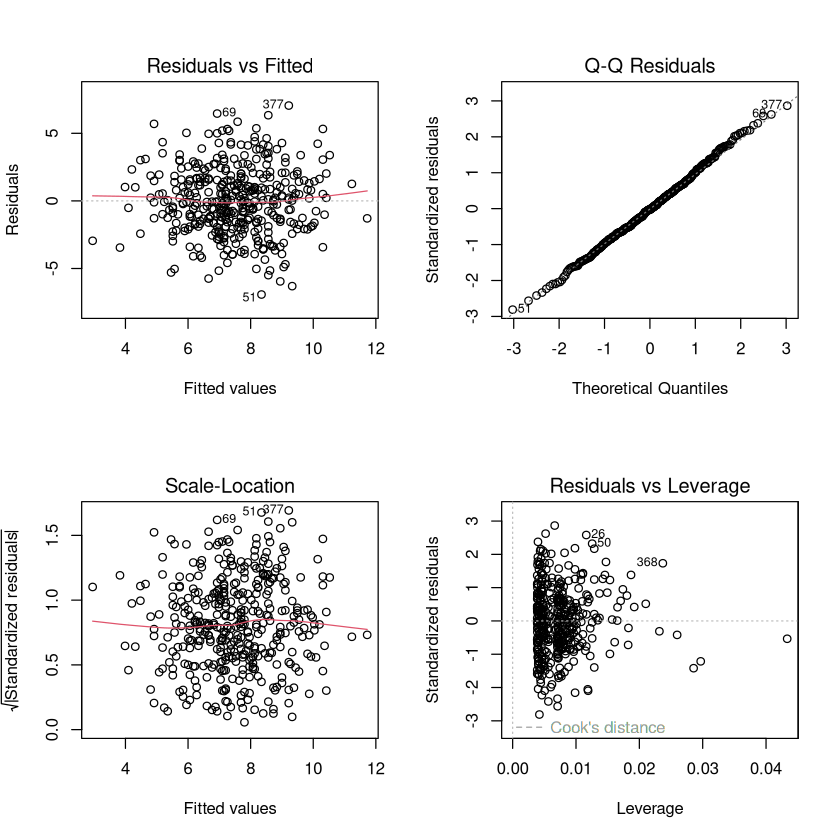

In [37]:
par(mfrow = c(2, 2))
plot(lm_carseats_best)
par(mfrow = c(1, 1))

1. Выбросы. На графиках Normal Q-Q и Residuals vs Fitted выделяются наблюдения 69, 377 и 51 с большими по модулю остатками (на хвостах Q-Q и дальше всех по вертикали). Это отдельные выбросы, но их немного, и красная линия остатков почти горизонтальна — модель не смещена.
2. Высокий рычаг. На Residuals vs Leverage справа есть точки с повышенным leverage (0.02–0.04), в частности 368, 50 и 26 — необычные комбинации `Price` и `US`, потенциально сильнее влияющие на коэффициенты.
3. Влиятельность. Все точки лежат внутри пунктирных границ расстояния Кука (ни одна не выходит за них и не близка к 1). Значит, наблюдений с критическим влиянием нет

Вывод: В модели присутствуют единичные выбросы и точки с высоким рычагом, однако все они лежат в пределах границ Кука, поэтому существенного влияния на коэффициенты не оказывают. Основное ограничение модели — она объясняет лишь около 24% дисперсии Sales